<a href="https://colab.research.google.com/github/ninilin2023/90801/blob/main/week6_visualization_in_class_ANSWER_KEY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 In-Class Exercise: Visualization

This exercise follows the slides, in the same order. For each part: read the **Task**, try it yourself, and use the **Hint** if you get stuck. The **Check** tells you what you should see.

**Setup:** run the cell below once. It downloads the same `weo.duckdb` database we used in Week 4 (tables: `countries`, `indicators`, `metrics`), imports plotly, and loads the Titanic passenger data (`passengers_df`) used in Parts 1 and 3.

In [ ]:
import requests
import duckdb
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Download the DuckDB database file locally
db_url = "https://github.com/ninilin2023/teaching/raw/refs/heads/main/weo.duckdb"
response = requests.get(db_url)
with open("weo.duckdb", "wb") as f:
    f.write(response.content)

# Make a connection to the database
conn = duckdb.connect("weo.duckdb")

# Load the Titanic passenger data (used in Parts 1 and 3)
passengers_url = "https://raw.githubusercontent.com/ninilin2023/teaching/refs/heads/main/datafiles-titanic.csv"
passengers_df = pd.read_csv(passengers_url)

# Put the classes in their natural order
passengers_df["class"] = pd.Categorical(
    passengers_df["class"],
    categories=["First", "Second", "Third"],
    ordered=True,
)


## Part 1: Build a Clean Chart, Step by Step

**Goal:** Turn a default seaborn chart into a clear chart. Each step builds on the last one, so copy your code into the next cell and add to it.

We will use the Titanic passenger data (`passengers_df`) loaded in Setup.

**Step 1: Basic chart.** Make a count plot of passengers by `embark_town`, split by `class` with `hue`.

`sns.countplot(data=df, x="column", hue="column")`

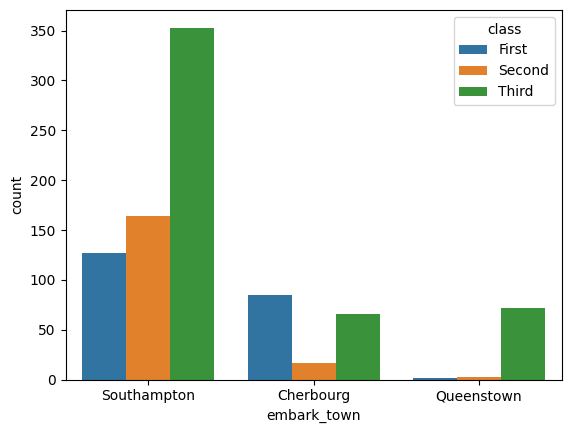

In [ ]:
ax = sns.countplot(data=passengers_df, x="embark_town", hue="class")
plt.show()

**Step 2: Title and takeaway.** Add a small chart title with `plt.title()` (font size 10) and a bold headline that states the takeaway with `plt.suptitle()` (font size 12).

* Title: `Titanic Passengers by Embark Town and Class`
* Headline: `Most First Class passengers boarded in Southampton or Cherbourg`

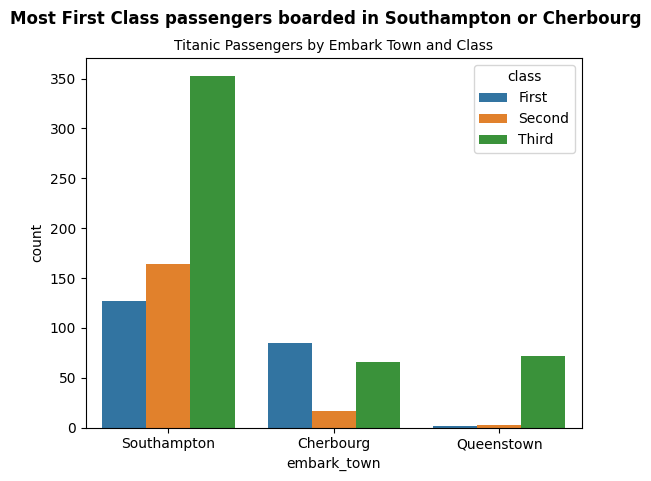

In [ ]:
ax = sns.countplot(data=passengers_df, x="embark_town", hue="class")
plt.title("Titanic Passengers by Embark Town and Class", fontsize=10)
plt.suptitle("Most First Class passengers boarded "
"in Southampton or Cherbourg", fontsize=12, fontweight="bold")
plt.show()

**Step 3: Remove clutter.** Remove both axis labels, remove the y-axis ticks, and hide the top, right, and left spines. Also sort the towns alphabetically with `order=sorted(...)`.

`ax.set(xlabel="", ylabel="")`

`ax.set_yticks([])`

`ax.spines[["top", "right", "left"]].set_visible(False)`

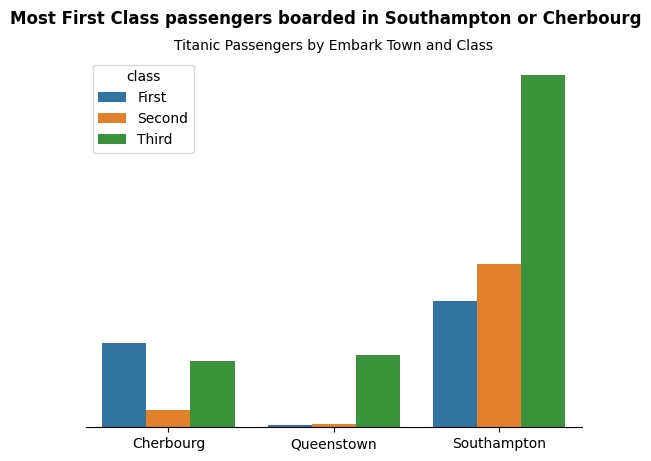

In [ ]:
towns = sorted(passengers_df["embark_town"].dropna().unique())
ax = sns.countplot(data=passengers_df, x="embark_town", hue="class", order=towns)

plt.title("Titanic Passengers by Embark Town and Class", fontsize=10)
plt.suptitle("Most First Class passengers boarded in Southampton or Cherbourg", fontsize=12, fontweight="bold")

ax.set(xlabel="", ylabel="")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

**Step 4: Data labels and legend.** Now that the y-axis is gone, print the value on top of each bar. Then move the legend to the upper left, in one column, inside a box. Finally, draw a light vertical line between each pair of towns to separate the groups.

`for container in ax.containers: ax.bar_label(container)`

`ax.legend(ncol=1, title="", loc="upper left", frameon=True)`

`for i in range(len(ax.get_xticklabels()) - 1): ax.axvline(x=i + 0.5, color="lightgray", alpha=0.3, linewidth=1)`

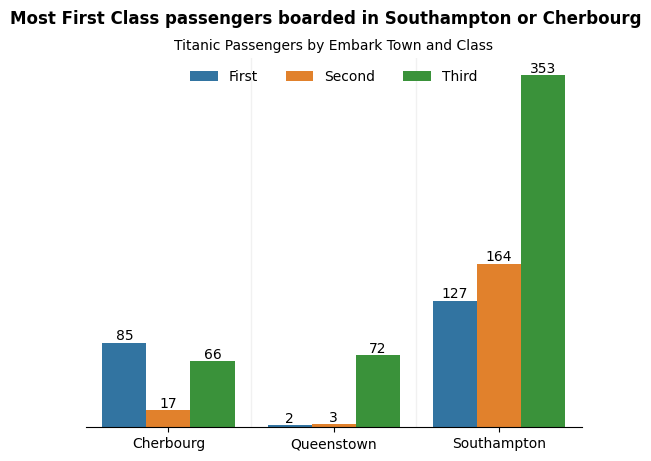

In [ ]:
ax = sns.countplot(data=passengers_df, x="embark_town", hue="class",
                   order=sorted(passengers_df["embark_town"].dropna().unique()))
plt.title("Titanic Passengers by Embark Town and Class", fontsize=10)
plt.suptitle("Most First Class passengers boarded in Southampton or Cherbourg", fontsize=12, fontweight="bold")

ax.set(xlabel="", ylabel="")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)

for container in ax.containers:
    ax.bar_label(container)

ax.legend(ncol=1, title="", loc="upper left", frameon=True)

# Add light vertical lines between the town groups
for i in range(len(ax.get_xticklabels()) - 1):
    ax.axvline(x=i + 0.5, color="lightgray", alpha=0.3, linewidth=1)
plt.show()

**Step 5: Choose your colors.** Pass your own `palette` (a list of 3 colors) that color-blind viewers can tell apart. Try `["#34495e", "#1abc9c", "#e74c3c"]`, or pick your own at colorbrewer2.org.

**Check:** Your final chart should look like the last chart on the slides.

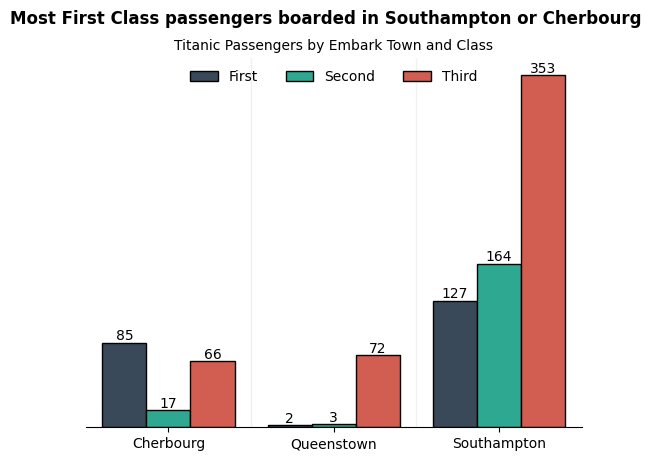

In [ ]:
palette = ["#34495e", "#1abc9c", "#e74c3c"]

ax = sns.countplot(data=passengers_df, x="embark_town", hue="class",
                   order=sorted(passengers_df["embark_town"].dropna().unique()),
                   edgecolor="black", linewidth=1, width=0.8, palette=palette)
plt.title("Titanic Passengers by Embark Town and Class", fontsize=10)
plt.suptitle("Most First Class passengers boarded in Southampton or Cherbourg", fontsize=12, fontweight="bold")

ax.set(xlabel="", ylabel="")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)

for container in ax.containers:
    ax.bar_label(container)

ax.legend(ncol=1, title="", loc="upper left", frameon=True)

# Add light vertical lines between the town groups
for i in range(len(ax.get_xticklabels()) - 1):
    ax.axvline(x=i + 0.5, color="lightgray", alpha=0.3, linewidth=1)
plt.show()

## Part 2: Sorted Horizontal Bar Chart Colored by Group

**Goal:** Show the 10 countries with the highest GDP per capita in 2023. Sort the bars from highest (top) to lowest (bottom) and color them by world region.

**Task A:** Write a SQL query that joins `metrics` and `countries`. Return each country's `name`, `region7`, and value (call it `gdp_pc`) where `subject_code = 'NGDPRPPPPC'` and `year = 2023`. Order from highest to lowest and keep 10 rows. Save it as `top_df`. Then add a column `gdp_pc_k` (the value divided by 1,000).

`SELECT c.name, c.region7, m.value AS gdp_pc FROM metrics AS m LEFT JOIN countries AS c ON m.iso_code = c.iso_code WHERE conditions ORDER BY m.value DESC LIMIT 10`

**Check:** Luxembourg is first (about 132.5 thousand) and Denmark is tenth (about 72.3 thousand).

In [ ]:
query = """
SELECT c.name, c.region7, m.value AS gdp_pc
FROM metrics AS m
LEFT JOIN countries AS c ON m.iso_code = c.iso_code
WHERE m.subject_code = 'NGDPRPPPPC' AND m.year = 2023
ORDER BY m.value DESC
LIMIT 10
"""

top_df = conn.sql(query).df()
top_df["gdp_pc_k"] = top_df["gdp_pc"] / 1000
top_df

,name,region7,gdp_pc,gdp_pc_k
0,Luxembourg,Europe and Central Asia,132467.663,132.467663
1,Singapore,East Asia and Pacific,129555.246,129.555246
2,Ireland,Europe and Central Asia,114412.856,114.412856
3,Macao SAR,East Asia and Pacific,104209.811,104.209811
4,Qatar,Middle East and North Africa,100906.134,100.906134
5,Norway,Europe and Central Asia,90085.089,90.085089
6,Switzerland,Europe and Central Asia,83850.029,83.850029
7,Brunei Darussalam,East Asia and Pacific,78273.100,78.273100
8,United States,North America,74112.916,74.112916
9,Denmark,Europe and Central Asia,72271.775,72.271775


**Task B:** Make the horizontal bar chart:

1. Set the theme to `darkgrid` and the palette to `colorblind` with `sns.set_theme(style="darkgrid", palette="colorblind")`.
2. Draw the bars with `sns.barplot()`. Put the numbers on **x** and the country names on **y** so the bars are horizontal. Color by region with `hue="region7"`. Add `dodge=False` so each bar keeps its full height.
3. Add data labels with **one decimal place**: `ax.bar_label(container, fmt="%.1f")`.
4. Add a descriptive title, remove the y-axis label, and rename the x-axis label to `GDP per capita (thousands, PPP)`.
5. Change the legend title to `Region`.

**Check:** The bars run from the longest (top) to the shortest (bottom), and the legend has 4 regions.

`sns.barplot(data=df, x="number_column", y="category_column", hue="group_column", dodge=False, ax=ax)`

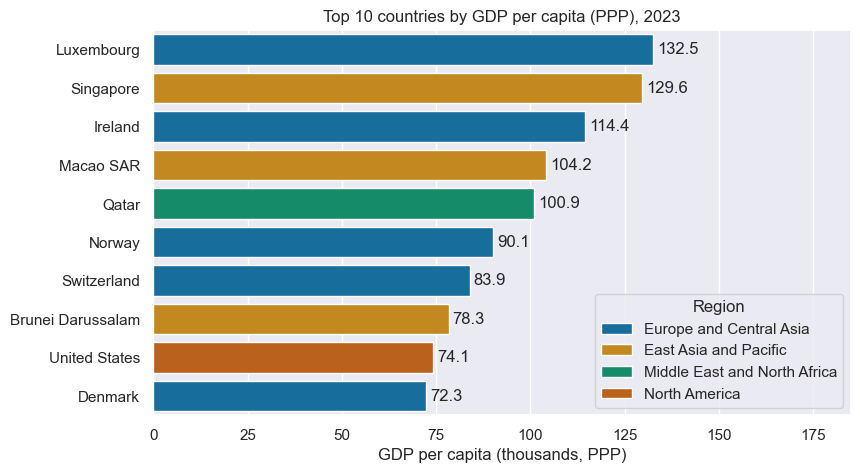

In [ ]:
sns.set_theme(style="darkgrid", palette="colorblind")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_df, x="gdp_pc_k", y="name", hue="region7", dodge=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.set_title("Top 10 countries by GDP per capita (PPP), 2023")
ax.set_xlabel("GDP per capita (thousands, PPP)")
ax.set_ylabel("")
ax.set_xlim(0, 185)                       # leave room for the legend
ax.legend(title="Region", loc="lower right")
plt.show()

## Part 3: A 2x2 Dashboard with subplots

**Goal:** Put four charts in one figure, using the Titanic data from Part 1.

**Task:** Create a figure with `plt.subplots(2, 2, figsize=(12, 8))`, then draw one seaborn chart in each panel by passing `ax=axes[row, col]`:

* top left: histogram of `fare`
* top right: box plot of `fare` by `class`
* bottom left: bar plot of `survived` by `class` (the bar height is the survival rate)
* bottom right: count plot of `embark_town`

Give each panel a title, remove each x-axis label, and finish with `plt.tight_layout()`.

`fig, axes = plt.subplots(2, 2, figsize=(12, 8))`

`sns.histplot(data=df, x="column", ax=axes[0, 0])`

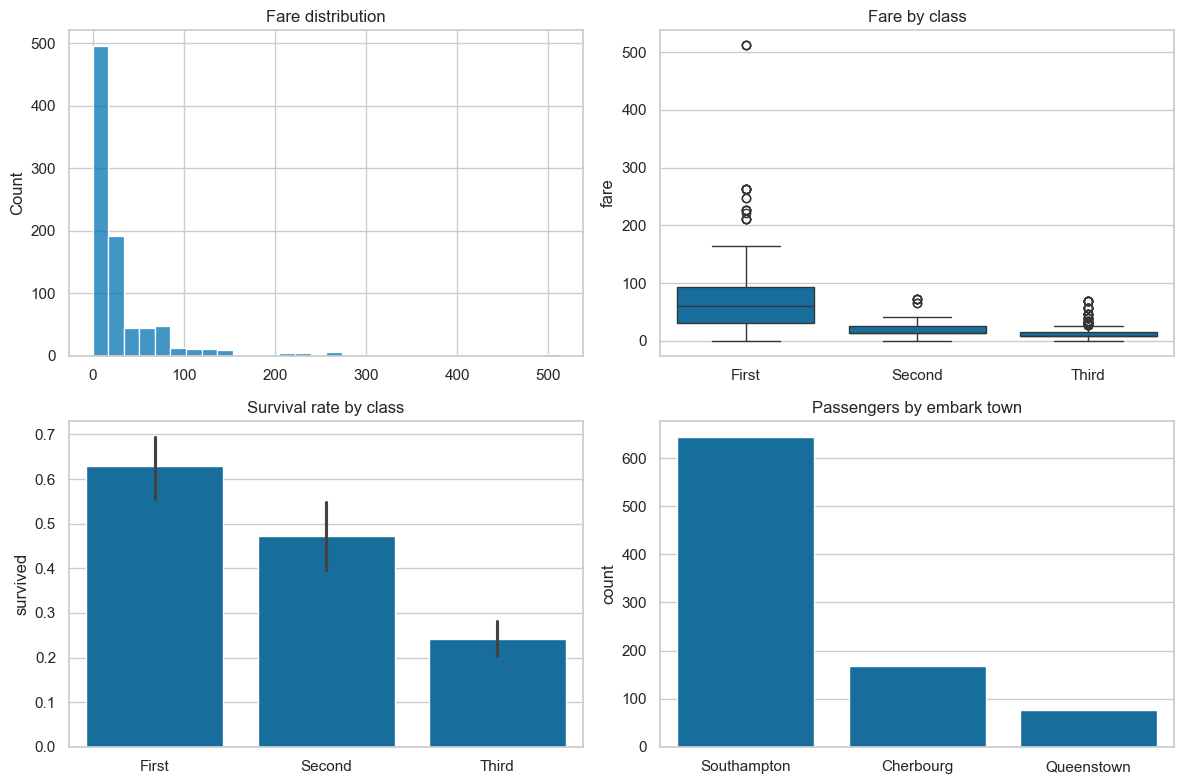

In [ ]:
sns.set_theme(style="whitegrid", palette="colorblind")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=passengers_df, x="fare", bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Fare distribution")

sns.boxplot(data=passengers_df, x="class", y="fare", ax=axes[0, 1])
axes[0, 1].set_title("Fare by class")

sns.barplot(data=passengers_df, x="class", y="survived", ax=axes[1, 0])
axes[1, 0].set_title("Survival rate by class")

sns.countplot(data=passengers_df, x="embark_town", ax=axes[1, 1])
axes[1, 1].set_title("Passengers by embark town")

for ax in axes.flat:
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

## Part 4: An Interactive Map with plotly

**Goal:** Map the 2023 unemployment rate for every country.

**Task A:** Query the `metrics` table for the unemployment rate (`subject_code = 'LUR'`) in `year = 2023`. Save it as `map_df`.

**Task B:** Use `plotly.express` to draw a map with `px.choropleth()`. The `iso_code` column holds 3-letter country codes, which is what plotly needs. Add a descriptive title, use the `reds` color scale, and hover over a country to see its code.

`fig = px.choropleth(map_df, locations="iso_code", color="value", hover_name="iso_code", color_continuous_scale="reds", title="text")`

`fig.show()`

**Try it:** Change the color scale to `temps`, `viridis`, or `blues`. To list all built-in scales, run `px.colors.named_colorscales()`.

In [ ]:
import plotly.express as px

query = """
SELECT *
FROM metrics
WHERE subject_code = 'LUR' AND year = 2023
"""
map_df = conn.sql(query).df()

fig = px.choropleth(
    map_df,
    locations="iso_code",
    color="value",
    hover_name="iso_code",
    color_continuous_scale="reds",
    labels={"value": "Unemployment rate (%)"},
    title="Unemployment rate by country, 2023",
)
fig.show()